# Tarea 6: EDA

> Uriel Aguilar Mauricio

Utilizando el dataset KC1, construye un pequeño reporte respondiendo:
- ¿Existen valores faltantes? ***NO***
- ¿Existen registros duplicados? ***SI***
- ¿Qué variables presentan valores extremos? ***e, v ,t***
- ¿Es conveniente escalar los datos? ***SI***
- ¿La variable Defective presenta desbalance? ***SI***
- Y finalmente elabora un pipeline de limpieza utilizando Pandas y Scikit-learn.

In [76]:
import pandas as pd
from scipy.io import arff
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler

In [56]:
data, meta = arff.loadarff("../data/raw/kc1.arff")

df = pd.DataFrame(data)

In [57]:
df.shape

(2109, 22)

In [58]:
df.head()

,loc,v(g),ev(g),iv(g),n,v,l,d,i,e,...,lOCode,lOComment,lOBlank,locCodeAndComment,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount,defects
0,1.1,1.4,1.4,1.4,1.3,1.30,1.30,1.30,1.30,1.30,...,2.0,2.0,2.0,2.0,1.2,1.2,1.2,1.2,1.4,b'false'
1,1.0,1.0,1.0,1.0,1.0,1.00,1.00,1.00,1.00,1.00,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,b'true'
2,83.0,11.0,1.0,11.0,171.0,927.89,0.04,23.04,40.27,21378.61,...,65.0,10.0,6.0,0.0,18.0,25.0,107.0,64.0,21.0,b'true'
3,46.0,8.0,6.0,8.0,141.0,769.78,0.07,14.86,51.81,11436.73,...,37.0,2.0,5.0,0.0,16.0,28.0,89.0,52.0,15.0,b'true'
4,25.0,3.0,1.0,3.0,58.0,254.75,0.11,9.35,27.25,2381.95,...,21.0,0.0,2.0,0.0,11.0,10.0,41.0,17.0,5.0,b'true'


## Valores faltantes

In [59]:
df.isna().sum()

loc                  0
v(g)                 0
ev(g)                0
iv(g)                0
n                    0
v                    0
l                    0
d                    0
i                    0
e                    0
b                    0
t                    0
lOCode               0
lOComment            0
lOBlank              0
locCodeAndComment    0
uniq_Op              0
uniq_Opnd            0
total_Op             0
total_Opnd           0
branchCount          0
defects              0
dtype: int64

***No existen valores faltantes***

## Valores duplicados

In [60]:
df.duplicated().sum()

np.int64(897)

In [61]:
df[df.duplicated(keep=False)]

,loc,v(g),ev(g),iv(g),n,v,l,d,i,e,...,lOCode,lOComment,lOBlank,locCodeAndComment,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount,defects
83,4.0,1.0,1.0,1.0,4.0,8.00,0.67,1.5,5.33,12.00,...,2.0,0.0,0.0,0.0,3.0,1.0,3.0,1.0,1.0,b'true'
92,4.0,1.0,1.0,1.0,4.0,8.00,0.67,1.5,5.33,12.00,...,2.0,0.0,0.0,0.0,3.0,1.0,3.0,1.0,1.0,b'true'
150,4.0,1.0,1.0,1.0,4.0,8.00,0.67,1.5,5.33,12.00,...,2.0,0.0,0.0,0.0,3.0,1.0,3.0,1.0,1.0,b'true'
160,3.0,1.0,1.0,1.0,1.0,0.00,0.00,0.0,0.00,0.00,...,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,b'true'
162,23.0,1.0,1.0,1.0,69.0,331.71,0.18,5.6,59.23,1857.56,...,13.0,0.0,0.0,0.0,8.0,20.0,41.0,28.0,1.0,b'true'
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2095,1.0,1.0,1.0,1.0,5.0,11.61,0.67,1.5,7.74,17.41,...,0.0,0.0,0.0,0.0,3.0,2.0,3.0,2.0,1.0,b'false'
2096,2.0,1.0,1.0,1.0,5.0,11.61,0.67,1.5,7.74,17.41,...,0.0,0.0,0.0,0.0,3.0,2.0,3.0,2.0,1.0,b'false'
2101,2.0,1.0,1.0,1.0,8.0,22.46,0.50,2.0,11.23,44.92,...,0.0,0.0,0.0,0.0,4.0,3.0,5.0,3.0,1.0,b'false'
2103,4.0,1.0,1.0,1.0,5.0,11.61,0.67,1.5,7.74,17.41,...,0.0,0.0,0.0,0.0,3.0,2.0,3.0,2.0,1.0,b'false'


***Existen valores duplicados***

## Valores atipicos

In [62]:
df.boxplot()

<Axes: >

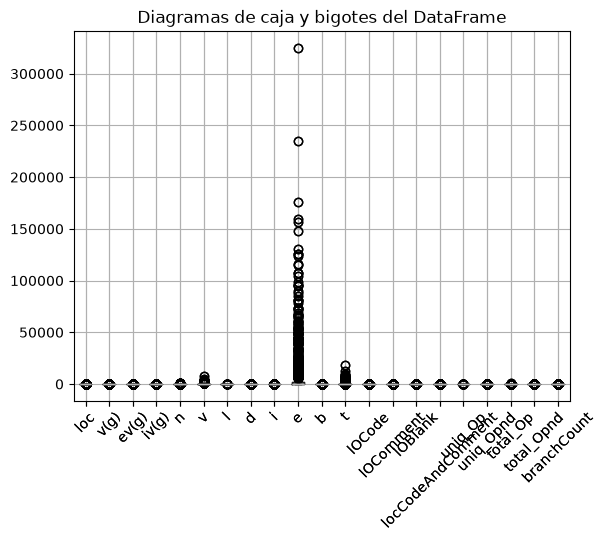

In [63]:
df.boxplot(figsize=(12, 6))
plt.title("Diagramas de caja y bigotes del DataFrame")
plt.xticks(rotation=45)
plt.show()

In [64]:
col = df.select_dtypes(include="number").drop(columns=["e"])

***e tiene valores extremos***

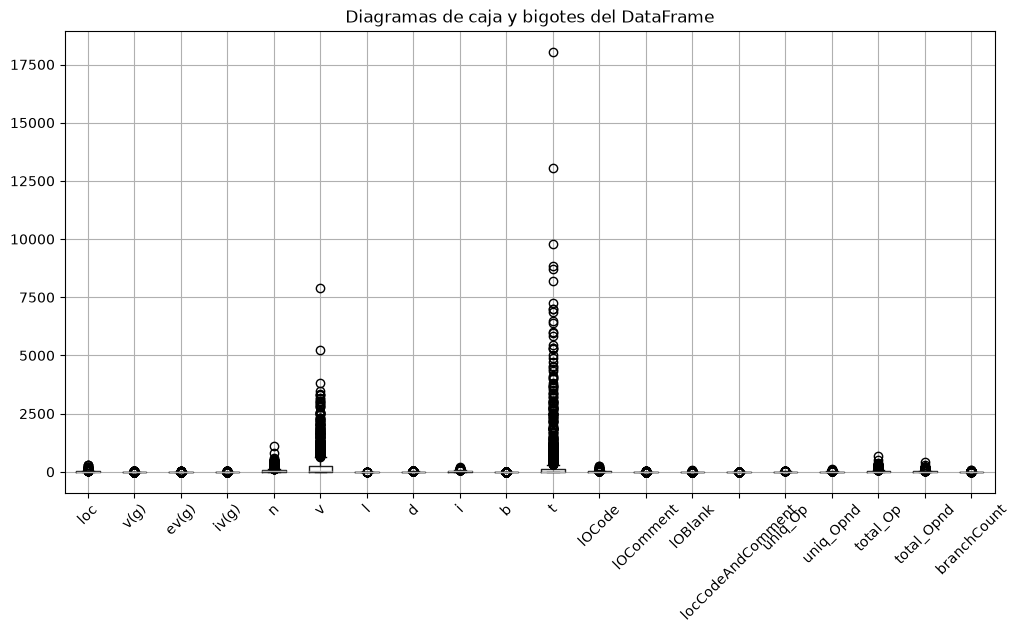

In [65]:
col.boxplot(figsize=(12, 6))

plt.title("Diagramas de caja y bigotes del DataFrame")
plt.xticks(rotation=45)
plt.show()

## Balanceo de clases

In [66]:
df["defects"].value_counts()

defects
b'false'    1783
b'true'      326
Name: count, dtype: int64

# PIPELINE DE LIMPIEZA

In [67]:
df_clean = df.copy()

***Eliminar registros duplicados***

In [68]:
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

***Convertir la variable objetivo a binario***

In [69]:
df_clean["defects"] = df_clean["defects"].apply(
    lambda x: x.decode("utf-8") if isinstance(x, bytes) else x
)

# Convertir a valores binarios
df_clean["defects"] = df_clean["defects"].map({
    "false": 0,
    "true": 1
})

***Separar la variable objetivo de las predictoras***

In [70]:
X = df_clean.drop(columns=["defects"])
y = df_clean["defects"]

***Pipeline para aplicar mediana a valores faltantes y escalamiento resistente a valores extremos***

In [71]:
pipeline_df = Pipeline(steps=[
    
    ("imputacion", SimpleImputer(strategy="median")),
    
    ("escalado", RobustScaler())
])


***Preprocesador***

In [72]:
preprocesador = ColumnTransformer(
    transformers=[
        ("numericas", pipeline_df, X.columns)
    ],
    remainder="drop"
)

preprocesador.set_output(transform="pandas")


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

***Separar los datos en train y test, para ello 80% para train y 20% para test***

In [73]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

***Aplicar el pipeline***

In [74]:
X_train_clean = preprocesador.fit_transform(X_train)
X_test_clean = preprocesador.transform(X_test)

***Verificar***

In [77]:
print("Duplicados después de limpieza:")
print(df_clean.duplicated().sum())

print("\nValores faltantes después del preprocesamiento:")
print(X_train_clean.isna().sum().sum())

print("\nDistribución de clases:")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True))

Duplicados después de limpieza:
0

Valores faltantes después del preprocesamiento:
0

Distribución de clases:
defects
0    717
1    252
Name: count, dtype: int64
defects
0    0.739938
1    0.260062
Name: proportion, dtype: float64


In [75]:
print("Dataset completo:")
print(y.value_counts(normalize=True))

print("\nEntrenamiento:")
print(y_train.value_counts(normalize=True))

print("\nPrueba:")
print(y_test.value_counts(normalize=True))

Dataset completo:
defects
0    0.740099
1    0.259901
Name: proportion, dtype: float64

Entrenamiento:
defects
0    0.739938
1    0.260062
Name: proportion, dtype: float64

Prueba:
defects
0    0.740741
1    0.259259
Name: proportion, dtype: float64


El análisis y preprocesamiento del conjunto de datos KC1 permitio identificar la calidad y preparación de los datos antes de utilizarlos en un modelo de aprendizaje automático. Se comprobó que no existen valores faltantes, aunque sí se encontraron registros duplicados, los cuales fueron eliminados para evitar redundancia en el análisis. Asimismo, se identificó la presencia de valores extremos en algunas variables numéricas, por lo que se decidió utilizar RobustScaler, ya que este método es menos sensible a los valores atípicos que otras técnicas de estandarización.

La variable objetivo defects fue transformada a una representación binaria para facilitar su uso en modelos de clasificación. Además, se observó un desbalance entre las clases, con una mayor proporción de módulos no defectuosos respecto a los defectuosos. Para conservar esta distribución tanto en el conjunto de entrenamiento como en el de prueba, se utilizó una división estratificada.

Finalmente, se construyó un pipeline de preprocesamiento mediante Pandas y Scikit-learn que integra la imputación de posibles valores faltantes, el escalamiento de las variables numéricas y la separación adecuada de los datos de entrenamiento y prueba. De esta manera, se obtiene un conjunto de datos para ser utilizado en la construcción y evaluación de modelos de clasificación de defectos de software.